In [1]:
import pandas as pd
import google_play_scraper

print("Environment setup successful!")
print("Pandas version:", pd.__version__)

Environment setup successful!
Pandas version: 3.0.6


In [3]:
import pandas as pd
from google_play_scraper import reviews, Sort

In [4]:
result, continuation_token = reviews(
    'notion.id',
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=100
)

print("Number of reviews:", len(result))
print("Continuation token available:", continuation_token is not None)

Number of reviews: 100
Continuation token available: True


In [5]:
df = pd.DataFrame(result)

print("Dataset shape:", df.shape)

print("\nAvailable columns:")
print(df.columns.tolist())

df.head()

Dataset shape: (100, 11)

Available columns:
['reviewId', 'userName', 'userImage', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'appVersion']


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,84e67b19-89f5-4b58-9dd5-8487eb67d69a,Thomas Daniel Ford,https://play-lh.googleusercontent.com/a-/ALV-U...,"I do want to use it fully, and as much as I ca...",5,0,0.6.4318,2026-11-19 18:26:58,None,None,0.6.4318
1,d6e7707a-bbc3-4b94-a82a-4cdd878f9aff,Debjeet Sanatani,https://play-lh.googleusercontent.com/a-/ALV-U...,"next level management app, trust me.. download...",5,0,0.6.4318,2026-11-19 16:25:27,None,None,0.6.4318
2,87e0dfd2-31f3-49b8-8192-0a93e2e3bca1,Gian Carlo,https://play-lh.googleusercontent.com/a-/ALV-U...,I wish the app was faster,3,0,0.6.4324,2026-11-19 15:40:55,None,None,0.6.4324
3,d4ae195f-c640-477f-9285-da564dc99e96,Cari Fisher,https://play-lh.googleusercontent.com/a/ACg8oc...,"got stuck in a sign-in loop, couldn't use the ...",1,0,0.6.4324,2026-11-19 14:13:23,None,None,0.6.4324
4,7656c536-3f01-4535-8d9b-d40243b3e5e8,Anna Garman,https://play-lh.googleusercontent.com/a-/ALV-U...,Was good for a while but now it crashes every ...,1,0,0.6.4324,2026-11-19 14:13:04,None,None,0.6.4324


In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nReview content examples:")
print(df[['content', 'score', 'at']].head(10).to_string(index=False))

Missing values:
reviewId                  0
userName                  0
userImage                 0
content                   0
score                     0
thumbsUpCount             0
reviewCreatedVersion     12
at                        0
replyContent            100
repliedAt               100
appVersion               12
dtype: int64

Review content examples:
                                                                                                                      content  score                  at
I do want to use it fully, and as much as I can without paying, some essential features for my intended use aren't available.      5 2026-11-19 18:26:58
                                                                        next level management app, trust me.. download it now      5 2026-11-19 16:25:27
                                                                                                    I wish the app was faster      3 2026-11-19 15:40:55
                         

In [7]:
next_result, next_token = reviews(
    'notion.id',
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=100,
    continuation_token=continuation_token
)

df_next = pd.DataFrame(next_result)

print("Second batch reviews:", len(df_next))
print("Next token available:", next_token is not None)

Second batch reviews: 100
Next token available: True


In [8]:
duplicate_count = df['reviewId'].isin(
    df_next['reviewId']
).sum()

print("Duplicate reviews:", duplicate_count)

Duplicate reviews: 0


In [9]:
duolingo_result, duolingo_token = reviews(
    'com.duolingo',
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=100
)

df_duolingo = pd.DataFrame(duolingo_result)

print("Number of reviews:", len(df_duolingo))
print("Number of columns:", len(df_duolingo.columns))
print("Continuation token available:", duolingo_token is not None)

Number of reviews: 100
Number of columns: 11
Continuation token available: True


In [10]:
print(df_duolingo.columns.tolist())

print("\nMissing values:")
print(df_duolingo.isnull().sum())

print("\nReview examples:")
print(
    df_duolingo[['content', 'score', 'at']]
    .head(10)
    .to_string(index=False)
)

['reviewId', 'userName', 'userImage', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'appVersion']

Missing values:
reviewId                  0
userName                  0
userImage                 0
content                   0
score                     0
thumbsUpCount             0
reviewCreatedVersion      7
at                        0
replyContent            100
repliedAt               100
appVersion                7
dtype: int64

Review examples:
                                                                                                                                                                                                                                                                                                                                                   content  score                  at
                                                                                                                          

In [11]:
duolingo_next_result, duolingo_next_token = reviews(
    'com.duolingo',
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=100,
    continuation_token=duolingo_token
)

df_duolingo_next = pd.DataFrame(duolingo_next_result)

print("Second batch reviews:", len(df_duolingo_next))
print("Next token available:", duolingo_next_token is not None)

Second batch reviews: 100
Next token available: True


In [12]:
duolingo_duplicates = df_duolingo['reviewId'].isin(
    df_duolingo_next['reviewId']
).sum()

print("Duplicate reviews:", duolingo_duplicates)

Duplicate reviews: 0


In [13]:
spotify_result, spotify_token = reviews(
    'com.spotify.music',
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=100
)

df_spotify = pd.DataFrame(spotify_result)

print("Number of reviews:", len(df_spotify))
print("Number of columns:", len(df_spotify.columns))
print("Continuation token available:", spotify_token is not None)

Number of reviews: 100
Number of columns: 11
Continuation token available: True


In [14]:
print(df_spotify.columns.tolist())

print("\nMissing values:")
print(df_spotify.isnull().sum())

print("\nReview examples:")
print(
    df_spotify[['content', 'score', 'at']]
    .head(10)
    .to_string(index=False)
)

['reviewId', 'userName', 'userImage', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'appVersion']

Missing values:
reviewId                 0
userName                 0
userImage                0
content                  0
score                    0
thumbsUpCount            0
reviewCreatedVersion    14
at                       0
replyContent            88
repliedAt               88
appVersion              14
dtype: int64

Review examples:
                                                               content  score                  at
                                                     regresen a DjLivi      4 2026-11-20 13:56:37
                                                              the best      5 2026-11-20 13:55:32
    Used to be great, now it's bloated, and has ads even on premium. 😖      3 2026-11-20 13:50:58
                                                   don't like the name      1 2026-11-20 13:45:22
                 

In [15]:
spotify_next_result, spotify_next_token = reviews(
    'com.spotify.music',
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=100,
    continuation_token=spotify_token
)

df_spotify_next = pd.DataFrame(spotify_next_result)

print("Second batch reviews:", len(df_spotify_next))
print("Next token available:", spotify_next_token is not None)

Second batch reviews: 100
Next token available: True


In [16]:
spotify_duplicates = df_spotify['reviewId'].isin(
    df_spotify_next['reviewId']
).sum()

print("Duplicate reviews:", spotify_duplicates)

Duplicate reviews: 0


In [17]:
from pathlib import Path

data_dir = Path("../data/raw")
data_dir.mkdir(parents=True, exist_ok=True)

notion_all = pd.concat([df, df_next], ignore_index=True)
duolingo_all = pd.concat(
    [df_duolingo, df_duolingo_next],
    ignore_index=True
)
spotify_all = pd.concat(
    [df_spotify, df_spotify_next],
    ignore_index=True
)

notion_all.to_csv(data_dir / "notion_reviews.csv", index=False)
duolingo_all.to_csv(data_dir / "duolingo_reviews.csv", index=False)
spotify_all.to_csv(data_dir / "spotify_reviews.csv", index=False)

print("Data saved successfully!")
print("Notion:", notion_all.shape)
print("Duolingo:", duolingo_all.shape)
print("Spotify:", spotify_all.shape)

Data saved successfully!
Notion: (200, 11)
Duolingo: (200, 11)
Spotify: (200, 11)


In [18]:
notion_all["app"] = "Notion"
duolingo_all["app"] = "Duolingo"
spotify_all["app"] = "Spotify"

all_reviews = pd.concat(
    [notion_all, duolingo_all, spotify_all],
    ignore_index=True
)

print("Combined dataset shape:", all_reviews.shape)
print("\nReviews by app:")
print(all_reviews["app"].value_counts())

Combined dataset shape: (600, 12)

Reviews by app:
app
Notion      200
Duolingo    200
Spotify     200
Name: count, dtype: int64


In [19]:
print("Total rows:", len(all_reviews))

print(
    "Duplicate review IDs:",
    all_reviews.duplicated(
        subset=["app", "reviewId"]
    ).sum()
)

print("\nUnique review IDs by app:")
print(
    all_reviews.groupby("app")["reviewId"].nunique()
)

Total rows: 600
Duplicate review IDs: 0

Unique review IDs by app:
app
Duolingo    200
Notion      200
Spotify     200
Name: reviewId, dtype: int64


In [21]:
all_reviews["content_length"] = (
    all_reviews["content"].astype(str).str.len()
)

print(
    all_reviews.groupby("app")["content_length"]
    .describe()
)

          count    mean         std  min    25%   50%     75%    max
app                                                                 
Duolingo  200.0   76.00  109.345380  2.0  13.75  34.0   73.25  499.0
Notion    200.0  110.41  120.598182  4.0  23.75  58.0  158.00  500.0
Spotify   200.0   79.25  110.100947  1.0   9.00  29.0  107.25  500.0


In [22]:
print(
    "Duplicate review IDs:",
    all_reviews.duplicated(
        subset=["app", "reviewId"]
    ).sum()
)

print("\nUnique review IDs by app:")
print(
    all_reviews.groupby("app")["reviewId"].nunique()
)

Duplicate review IDs: 0

Unique review IDs by app:
app
Duolingo    200
Notion      200
Spotify     200
Name: reviewId, dtype: int64


In [23]:
empty_reviews = (
    all_reviews["content"]
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)

print("Empty review content:", empty_reviews)

Empty review content: 0


In [24]:
%pip install vaderSentiment


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [25]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("VADER initialized successfully!")

VADER initialized successfully!


In [26]:
%pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 13.1 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993332 sha256=37178cc7005b8805e6ec476f47eb5b0691e90bfc258d821575bec63c7369cf3c
  Stored in directory: /Users/apple/Library/Caches/pip/wheels/eb/87/25/2dddf1c94e1786054e25022ec5530bfed52bad86d882999c48
Successfully built langdetect

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [28]:
from langdetect import detect, DetectorFactory

DetectorFactory.seed = 0

def detect_language(text):
    try:
        return detect(str(text))
    except:
        return "unknown"

In [29]:
all_reviews["language"] = all_reviews["content"].apply(detect_language)

print("Language detection completed!")
print(all_reviews[["app", "content", "language"]].head(10))

Language detection completed!
      app                                            content language
0  Notion  I do want to use it fully, and as much as I ca...       en
1  Notion  next level management app, trust me.. download...       en
2  Notion                          I wish the app was faster       en
3  Notion  got stuck in a sign-in loop, couldn't use the ...       en
4  Notion  Was good for a while but now it crashes every ...       en
5  Notion                           very useful for students       en
6  Notion  used to love notion but i hate how ai forward ...       en
7  Notion                            it was agood experience       en
8  Notion                                           not good       af
9  Notion  Flexible workspace for notes,docs and organizi...       en


In [30]:
language_summary = (
    all_reviews.groupby(["app", "language"])
    .size()
    .unstack(fill_value=0)
)

print(language_summary)

language  af  ar  bn  ca  cs  cy  da  de   en  es  ...  sk  sl  so  sq  sv  \
app                                                ...                       
Duolingo   7   1   0   0   2   1   1   0  143   1  ...   0   2  10   1   1   
Notion     6   1   0   1   0   0   0   0  157   0  ...   0   0   7   0   0   
Spotify   10   0   1   4   3   2   0   1  127   0  ...   3   1  12   0   1   

language  sw  tl  tr  unknown  vi  
app                                
Duolingo   2   1   1        3   0  
Notion     1   1   1        0   0  
Spotify    1   0   0        5   1  

[3 rows x 35 columns]


In [31]:
language_check = (
    all_reviews.groupby("app")["language"]
    .value_counts()
    .unstack(fill_value=0)
)

summary = pd.DataFrame(index=language_check.index)

summary["total"] = all_reviews.groupby("app").size()
summary["english"] = language_check["en"]
summary["unknown"] = language_check["unknown"]
summary["non_english"] = (
    summary["total"] - summary["english"] - summary["unknown"]
)
summary["english_pct"] = (
    summary["english"] / summary["total"] * 100
).round(2)

print(summary)

          total  english  unknown  non_english  english_pct
app                                                        
Duolingo    200      143        3           54         71.5
Notion      200      157        0           43         78.5
Spotify     200      127        5           68         63.5


In [32]:
non_english_sample = all_reviews[
    (all_reviews["language"] != "en") &
    (all_reviews["language"] != "unknown")
][["app", "content", "language", "content_length"]]

print(non_english_sample.head(20).to_string(index=False))

   app                                                                                                                                                              content language  content_length
Notion                                                                                                                                                             not good       af               8
Notion IMPOSSIBLE de se connecter sur Notion depuis hier avec mon compte Google. Ça charge et ça n'affiche pas de nouvelles page du tout ça reste sur la page de connexion.       fr             164
Notion                                                                                                                                                       Excellent 👌🏼👍🏼       ca              14
Notion                                                                                                                                                           great nice       ro              10
Notion         

In [33]:
suspected_reviews = all_reviews[
    (all_reviews["language"] != "en") &
    (all_reviews["content_length"] <= 20)
][["app", "content", "language", "content_length"]]

print(suspected_reviews.to_string(index=False))

     app              content language  content_length
  Notion             not good       af               8
  Notion       Excellent 👌🏼👍🏼       ca              14
  Notion           great nice       ro              10
  Notion        best app ever       no              13
  Notion         let's hope 😂       fr              12
  Notion                bagus       tl               5
  Notion Əla qeyd proqramıdır       tr              20
  Notion                Good.       so               5
  Notion                بحبكم       ar               5
  Notion                 good       so               4
  Notion                gooo👍       so               5
  Notion    I love you Notion       fr              17
  Notion              useless       et               7
  Notion                super       ro               5
  Notion           ai is paid       lt              10
  Notion                 Good       so               4
  Notion            Very good       af               9
  Notion  

In [34]:
english_phrases = [
    "not good", "excellent", "great nice", "best app ever",
    "let's hope", "good", "gooo", "i love you notion",
    "useless", "super", "ai is paid", "very good",
    "amazing", "best for notes", "verry good app",
    "useful app", "fantastic", "best app forever",
    "wonderful", "so good", "good app", "super cool",
    "very happy", "i love it", "dope", "nice app",
    "so interesting", "super awesome", "great app",
    "perfect", "very nice", "great lessons", "good one",
    "i love music", "best app", "not so good",
    "nice music", "fabulous", "awesome", "the best",
    "excellent!!!", "very satisfied", "amazing music app"
]

normalized_content = (
    all_reviews["content"]
    .str.lower()
    .str.strip()
)

all_reviews["language_final"] = all_reviews["language"]

all_reviews.loc[
    normalized_content.isin(english_phrases),
    "language_final"
] = "en"

print(
    all_reviews["language_final"]
    .value_counts()
    .head(15)
)

language_final
en         489
so          13
af          13
ro           8
unknown      8
pl           7
no           6
fr           5
nl           5
pt           4
ru           4
id           4
it           4
ca           3
sw           3
Name: count, dtype: int64


In [35]:
english_reviews = all_reviews[
    all_reviews["language_final"] == "en"
].copy()

print("English reviews:", len(english_reviews))
print("\nReviews by app:")
print(english_reviews["app"].value_counts())

print("\nSample reviews:")
print(english_reviews[["app", "content", "score"]].head(10))


English reviews: 489

Reviews by app:
app
Notion      175
Duolingo    161
Spotify     153
Name: count, dtype: int64

Sample reviews:
      app                                            content  score
0  Notion  I do want to use it fully, and as much as I ca...      5
1  Notion  next level management app, trust me.. download...      5
2  Notion                          I wish the app was faster      3
3  Notion  got stuck in a sign-in loop, couldn't use the ...      1
4  Notion  Was good for a while but now it crashes every ...      1
5  Notion                           very useful for students      5
6  Notion  used to love notion but i hate how ai forward ...      2
7  Notion                            it was agood experience      5
8  Notion                                           not good      1
9  Notion  Flexible workspace for notes,docs and organizi...      5


In [36]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

sentiment_scores = english_reviews["content"].apply(
    analyzer.polarity_scores
)

sentiment_df = pd.DataFrame(sentiment_scores.tolist())

english_reviews = pd.concat(
    [english_reviews.reset_index(drop=True),
     sentiment_df.reset_index(drop=True)],
    axis=1
)

print(
    english_reviews[
        ["app", "content", "score", "pos", "neu", "neg", "compound"]
    ].head(10)
)

      app                                            content  score    pos  \
0  Notion  I do want to use it fully, and as much as I ca...      5  0.053   
1  Notion  next level management app, trust me.. download...      5  0.292   
2  Notion                          I wish the app was faster      3  0.351   
3  Notion  got stuck in a sign-in loop, couldn't use the ...      1  0.000   
4  Notion  Was good for a while but now it crashes every ...      1  0.130   
5  Notion                           very useful for students      5  0.516   
6  Notion  used to love notion but i hate how ai forward ...      2  0.147   
7  Notion                            it was agood experience      5  0.000   
8  Notion                                           not good      1  0.000   
9  Notion  Flexible workspace for notes,docs and organizi...      5  0.353   

     neu    neg  compound  
0  0.947  0.000    0.0772  
1  0.708  0.000    0.5106  
2  0.649  0.000    0.4019  
3  0.818  0.182   -0.2500  
4

In [37]:
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

english_reviews["sentiment"] = (
    english_reviews["compound"].apply(classify_sentiment)
)

print(english_reviews[["app", "content", "compound", "sentiment"]].head(10))

      app                                            content  compound  \
0  Notion  I do want to use it fully, and as much as I ca...    0.0772   
1  Notion  next level management app, trust me.. download...    0.5106   
2  Notion                          I wish the app was faster    0.4019   
3  Notion  got stuck in a sign-in loop, couldn't use the ...   -0.2500   
4  Notion  Was good for a while but now it crashes every ...    0.2382   
5  Notion                           very useful for students    0.4927   
6  Notion  used to love notion but i hate how ai forward ...   -0.5346   
7  Notion                            it was agood experience    0.0000   
8  Notion                                           not good   -0.3412   
9  Notion  Flexible workspace for notes,docs and organizi...    0.7184   

  sentiment  
0  Positive  
1  Positive  
2  Positive  
3  Negative  
4  Positive  
5  Positive  
6  Negative  
7   Neutral  
8  Negative  
9  Positive  


In [38]:
sentiment_summary = pd.crosstab(
    english_reviews["app"],
    english_reviews["sentiment"],
    normalize="index"
) * 100

print(sentiment_summary.round(2))

sentiment  Negative  Neutral  Positive
app                                   
Duolingo      14.29    13.66     72.05
Notion        20.00    10.86     69.14
Spotify       18.95    11.76     69.28


In [39]:
def classify_rating(score):
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

english_reviews["rating_sentiment"] = (
    english_reviews["score"].apply(classify_rating)
)

In [40]:
comparison = pd.crosstab(
    english_reviews["rating_sentiment"],
    english_reviews["sentiment"],
    margins=True
)

print(comparison)

sentiment         Negative  Neutral  Positive  All
rating_sentiment                                  
Negative                61       23        34  118
Neutral                 10        7        21   38
Positive                16       29       288  333
All                     87       59       343  489


In [41]:
mismatch_reviews = english_reviews[
    english_reviews["rating_sentiment"] != english_reviews["sentiment"]
].copy()

print("Number of mismatched reviews:", len(mismatch_reviews))

print(
    mismatch_reviews[
        ["app", "content", "score", "compound",
         "rating_sentiment", "sentiment"]
    ].head(20).to_string(index=False)
)

Number of mismatched reviews: 133
   app                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    content  score  compound rating_sentiment sentiment
Notion                                                                                                                                                                                                                                                                                                                                                                                                                                                  

In [42]:
mismatch_reviews["mismatch_type"] = (
    mismatch_reviews["rating_sentiment"]
    + " rating / "
    + mismatch_reviews["sentiment"]
    + " text"
)

mismatch_summary = pd.crosstab(
    mismatch_reviews["app"],
    mismatch_reviews["mismatch_type"]
)

print(mismatch_summary)
print("\nTotal mismatches by app:")
print(mismatch_summary.sum(axis=1))

mismatch_type  Negative rating / Neutral text  \
app                                             
Duolingo                                    5   
Notion                                      9   
Spotify                                     9   

mismatch_type  Negative rating / Positive text  \
app                                              
Duolingo                                     8   
Notion                                      12   
Spotify                                     14   

mismatch_type  Neutral rating / Negative text  Neutral rating / Positive text  \
app                                                                             
Duolingo                                    0                               3   
Notion                                      3                              10   
Spotify                                     7                               8   

mismatch_type  Positive rating / Negative text  Positive rating / Neutral text  
app             

In [43]:
issue_keywords = {
    "Performance": [
        "slow", "lag", "laggy", "freeze", "freezing",
        "crash", "crashes", "crashing", "loading"
    ],
    "Login and Access": [
        "login", "log in", "sign in", "sign-in",
        "password", "account", "locked out"
    ],
    "Pricing": [
        "price", "pricing", "expensive", "subscription",
        "paid", "payment", "cost", "fee"
    ],
    "Features and Functionality": [
        "feature", "function", "update", "missing",
        "sync", "integration", "notification"
    ],
    "Usability": [
        "confusing", "difficult", "hard to use",
        "complicated", "user friendly", "interface"
    ]
}

In [44]:
negative_reviews = english_reviews[
    english_reviews["sentiment"] == "Negative"
].copy()

def identify_issues(text):
    text = str(text).lower()
    matched_issues = []

    for issue, keywords in issue_keywords.items():
        if any(keyword in text for keyword in keywords):
            matched_issues.append(issue)

    return matched_issues

negative_reviews["issues"] = (
    negative_reviews["content"].apply(identify_issues)
)

print("Total negative reviews:", len(negative_reviews))

print(
    negative_reviews[
        ["app", "content", "sentiment", "issues"]
    ].head(15).to_string(index=False)
)

Total negative reviews: 87
   app                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              content sentiment                                         issues
Notion                                                                                                                                                                                                                                                                                                                                                                                                                  

In [47]:
issue_exploded = negative_reviews[
    ["app", "issues"]
].copy()

issue_exploded = issue_exploded.explode("issues").reset_index(drop=True)

issue_exploded = issue_exploded.dropna(subset=["issues"])

issue_summary = (
    issue_exploded
    .groupby(["app", "issues"])
    .size()
    .unstack(fill_value=0)
)

print(issue_summary)

issues    Features and Functionality  Login and Access  Performance  Pricing  \
app                                                                            
Duolingo                           3                 0            0        1   
Notion                            10                 6            9        1   
Spotify                            4                 2            1        7   

issues    Usability  
app                  
Duolingo          0  
Notion            1  
Spotify           1  


In [48]:
issue_percentage = (
    issue_summary.div(issue_summary.sum(axis=1), axis=0) * 100
).round(2)

print(issue_percentage)

issues    Features and Functionality  Login and Access  Performance  Pricing  \
app                                                                            
Duolingo                       75.00              0.00         0.00    25.00   
Notion                         37.04             22.22        33.33     3.70   
Spotify                        26.67             13.33         6.67    46.67   

issues    Usability  
app                  
Duolingo       0.00  
Notion         3.70  
Spotify        6.67  


In [49]:
unclassified = negative_reviews[
    negative_reviews["issues"].apply(len) == 0
]

print("Unclassified negative reviews:", len(unclassified))

print(
    unclassified[["app", "content"]]
    .head(10)
    .to_string(index=False)
)

Unclassified negative reviews: 50
   app                                                                                                                                                                                                                                                                                                                                          content
Notion                                                                                                                                                                                                                                                                                         used to love notion but i hate how ai forward its become
Notion                                                                                                                                                                                                                                                                                

In [50]:
issue_keywords = {
    "Performance": [
        "slow", "lag", "laggy", "freeze", "freezing",
        "crash", "crashes", "crashing", "loading",
        "buggy", "unresponsive", "stuck"
    ],
    "Login and Access": [
        "login", "log in", "logging in", "sign in",
        "sign-in", "signing in", "password",
        "account", "locked out", "sign up", "signing up"
    ],
    "Pricing": [
        "price", "pricing", "expensive", "subscription",
        "paid", "payment", "cost", "fee", "overpriced",
        "too expensive"
    ],
    "Features and Functionality": [
        "feature", "function", "update", "missing",
        "sync", "integration", "notification",
        "text size", "line break", "search",
        "find and replace", "autocorrect"
    ],
    "Usability": [
        "confusing", "difficult", "hard to use",
        "complicated", "user friendly", "interface",
        "annoying", "frustrating"
    ],
    "Data Loss and Reliability": [
        "data loss", "lost data", "deleted",
        "missing notes", "lost notes", "recover",
        "recovery", "cannot be trusted", "unsafe"
    ],
    "Bugs and Errors": [
        "bug", "bugs", "buggy", "glitch",
        "glitching", "not working", "stopped working",
        "doesn't work", "does not work", "error",
        "broken", "malfunction"
    ]
}

In [51]:
negative_reviews["issues"] = negative_reviews["content"].apply(
    identify_issues
)

In [52]:
unclassified = negative_reviews[
    negative_reviews["issues"].apply(len) == 0
]

print("Unclassified negative reviews:", len(unclassified))
print(
    unclassified[["app", "content"]]
    .head(15)
    .to_string(index=False)
)

Unclassified negative reviews: 38
     app                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        content
  Notion                                                                                                                                                                                                                                                                                                                                                                                                                                       used to love notion but i hate how ai forward i

In [53]:
print(
    unclassified[["app", "content"]]
    .to_string(index=False)
)

     app                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        content
  Notion                                                                                                                                                                                                                                                                                                                                                                                                                                       used to love notion but i hate how ai forward its become
  Notion                

In [54]:
sentiment_check = negative_reviews[
    negative_reviews["content"].str.contains(
        "10/10|only music app|fix my mood|fun as hell",
        case=False,
        na=False
    )
]

print(
    sentiment_check[
        ["app", "content", "score", "compound", "sentiment"]
    ].to_string(index=False)
)

     app                                                                 content  score  compound sentiment
Duolingo honestly fun as hell I don't even care about learning languages anymore      5   -0.2330  Negative
 Spotify                                   10/10 the only music app ill ever use      5   -0.4215  Negative
 Spotify      It become my part of life and always fix my mood when i am sad ...      5   -0.4767  Negative


In [55]:
english_reviews["sentiment_final"] = english_reviews["sentiment"]

english_reviews["validation_method"] = "VADER"

manual_corrections = {
    "honestly fun as hell I don't even care about learning languages anymore": "Positive",
    "10/10 the only music app ill ever use": "Positive",
    "It become my part of life and always fix my mood when i am sad ...": "Positive"
}

for review, corrected_sentiment in manual_corrections.items():
    mask = english_reviews["content"] == review
    english_reviews.loc[mask, "sentiment_final"] = corrected_sentiment
    english_reviews.loc[mask, "validation_method"] = "Manual correction"

In [56]:
print(
    english_reviews[
        english_reviews["validation_method"] == "Manual correction"
    ][
        ["app", "content", "sentiment", "sentiment_final", "validation_method"]
    ].to_string(index=False)
)

     app                                                                 content sentiment sentiment_final validation_method
Duolingo honestly fun as hell I don't even care about learning languages anymore  Negative        Positive Manual correction
 Spotify                                   10/10 the only music app ill ever use  Negative        Positive Manual correction
 Spotify      It become my part of life and always fix my mood when i am sad ...  Negative        Positive Manual correction


In [57]:
print("Original VADER sentiment:")
print(
    english_reviews["sentiment"]
    .value_counts()
    .sort_index()
)

print("\nFinal sentiment after manual corrections:")
print(
    english_reviews["sentiment_final"]
    .value_counts()
    .sort_index()
)

Original VADER sentiment:
sentiment
Negative     87
Neutral      59
Positive    343
Name: count, dtype: int64

Final sentiment after manual corrections:
sentiment_final
Negative     84
Neutral      59
Positive    346
Name: count, dtype: int64


In [58]:
original_distribution = pd.crosstab(
    english_reviews["app"],
    english_reviews["sentiment"],
    normalize="index"
) * 100

final_distribution = pd.crosstab(
    english_reviews["app"],
    english_reviews["sentiment_final"],
    normalize="index"
) * 100

print("Original distribution:")
print(original_distribution.round(2))

print("\nFinal distribution:")
print(final_distribution.round(2))

Original distribution:
sentiment  Negative  Neutral  Positive
app                                   
Duolingo      14.29    13.66     72.05
Notion        20.00    10.86     69.14
Spotify       18.95    11.76     69.28

Final distribution:
sentiment_final  Negative  Neutral  Positive
app                                         
Duolingo            13.66    13.66     72.67
Notion              20.00    10.86     69.14
Spotify             17.65    11.76     70.59


In [59]:
negative_reviews_final = english_reviews[
    english_reviews["sentiment_final"] == "Negative"
].copy()

print("Original negative reviews:", len(negative_reviews))
print("Final negative reviews:", len(negative_reviews_final))

print("\nNegative reviews by app:")
print(negative_reviews_final["app"].value_counts())

Original negative reviews: 87
Final negative reviews: 84

Negative reviews by app:
app
Notion      35
Spotify     27
Duolingo    22
Name: count, dtype: int64


In [60]:
negative_reviews_final["issues"] = (
    negative_reviews_final["content"].apply(identify_issues)
)

issue_exploded_final = (
    negative_reviews_final[["app", "issues"]]
    .copy()
    .explode("issues")
    .reset_index(drop=True)
)

issue_exploded_final = issue_exploded_final.dropna(
    subset=["issues"]
)

issue_summary_final = (
    issue_exploded_final
    .groupby(["app", "issues"])
    .size()
    .unstack(fill_value=0)
)

print(issue_summary_final)

issues    Bugs and Errors  Data Loss and Reliability  \
app                                                    
Duolingo                1                          0   
Notion                 10                          1   
Spotify                 1                          1   

issues    Features and Functionality  Login and Access  Performance  Pricing  \
app                                                                            
Duolingo                           3                 0            0        1   
Notion                            15                 7           12        1   
Spotify                            4                 2            1        7   

issues    Usability  
app                  
Duolingo          0  
Notion            6  
Spotify           3  


In [61]:
issue_percentage_final = (
    issue_summary_final.div(
        issue_summary_final.sum(axis=1), axis=0
    ) * 100
).round(2)

print(issue_percentage_final)

issues    Bugs and Errors  Data Loss and Reliability  \
app                                                    
Duolingo            20.00                       0.00   
Notion              19.23                       1.92   
Spotify              5.26                       5.26   

issues    Features and Functionality  Login and Access  Performance  Pricing  \
app                                                                            
Duolingo                       60.00              0.00         0.00    20.00   
Notion                         28.85             13.46        23.08     1.92   
Spotify                        21.05             10.53         5.26    36.84   

issues    Usability  
app                  
Duolingo       0.00  
Notion        11.54  
Spotify       15.79  


In [62]:
unclassified_final = negative_reviews_final[
    negative_reviews_final["issues"].apply(len) == 0
]

print("Unclassified negative reviews:", len(unclassified_final))

print(
    unclassified_final[["app", "content"]]
    .to_string(index=False)
)

Unclassified negative reviews: 35
     app                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        content
  Notion                                                                                                                                                                                                                                                                                                                                                                                                                                       used to love notion but i hate how ai forward i

In [63]:
print("Total negative reviews by app:")
print(negative_reviews_final["app"].value_counts())

print("\nClassified reviews by app:")
print(
    negative_reviews_final[
        negative_reviews_final["issues"].apply(len) > 0
    ]["app"].value_counts()
)

Total negative reviews by app:
app
Notion      35
Spotify     27
Duolingo    22
Name: count, dtype: int64

Classified reviews by app:
app
Notion      30
Spotify     15
Duolingo     4
Name: count, dtype: int64


In [64]:
unclassified_final = negative_reviews_final[
    negative_reviews_final["issues"].apply(len) == 0
]

print(
    unclassified_final[["app", "content"]]
    .to_string(index=False)
)

     app                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        content
  Notion                                                                                                                                                                                                                                                                                                                                                                                                                                       used to love notion but i hate how ai forward its become
  Notion                

In [65]:
issue_keywords = {
    "Performance": [
        "slow", "lag", "laggy", "freeze", "freezing",
        "crash", "crashes", "crashing", "loading",
        "buggy", "unresponsive", "stuck",
        "cpu", "battery", "heats up"
    ],

    "Login and Access": [
        "login", "log in", "logging in", "sign in",
        "sign-in", "signing in", "password",
        "account", "locked out", "sign up", "signing up"
    ],

    "Pricing": [
        "price", "pricing", "expensive", "subscription",
        "paid", "payment", "cost", "fee", "overpriced",
        "too expensive", "pay", "paying", "premium",
        "free version", "free options", "yearly"
    ],

    "Features and Functionality": [
        "feature", "function", "update", "missing",
        "sync", "integration", "notification",
        "text size", "line break", "search",
        "find and replace", "autocorrect",
        "copy", "widget", "voice recognition",
        "calibration", "rating system"
    ],

    "Usability": [
        "confusing", "difficult", "hard to use",
        "complicated", "user friendly", "interface",
        "annoying", "frustrating", "too many tabs",
        "too many screens", "click through",
        "learning curve", "easy to use"
    ],

    "Data Loss and Reliability": [
        "data loss", "lost data", "deleted",
        "missing notes", "lost notes", "recover",
        "recovery", "cannot be trusted", "unsafe"
    ],

    "Bugs and Errors": [
        "bug", "bugs", "buggy", "glitch",
        "glitching", "not working", "stopped working",
        "doesn't work", "does not work", "error",
        "broken", "malfunction"
    ],

    "Advertising": [
        "ads", "advertisement", "advertisements",
        "bombarded with ads", "too many ads",
        "watching ads", "ad-free"
    ],

    "Content Quality": [
        "content quality", "translation", "inaccurate",
        "wrong translation", "wrong answer",
        "course quality", "curriculum", "lesson",
        "lessons", "learning", "teach",
        "teaching", "nonsense", "unusable",
        "ai slop", "voice recognition"
    ],

    "Recommendations": [
        "algorithm", "recommendation", "recommendations",
        "relevant selections", "irrelevant",
        "not relevant", "suggestions"
    ],

    "Playback Experience": [
        "shuffle", "repeating the song", "repeat the song",
        "skips", "skipping", "autoplay",
        "starts playing music", "song", "songs"
    ],

    "Product Design": [
        "icon", "design", "dark patterns",
        "product direction", "ai forward",
        "too many tabs", "vibrations",
        "character", "product managers"
    ]
}

In [66]:
negative_reviews_final["issues"] = (
    negative_reviews_final["content"].apply(identify_issues)
)

In [67]:
issue_exploded_final = (
    negative_reviews_final[["app", "issues"]]
    .explode("issues")
    .dropna(subset=["issues"])
    .reset_index(drop=True)
)

issue_summary_final = (
    issue_exploded_final
    .groupby(["app", "issues"])
    .size()
    .unstack(fill_value=0)
)

print(issue_summary_final)

issues    Advertising  Bugs and Errors  Content Quality  \
app                                                       
Duolingo            3                1                8   
Notion              0               10                2   
Spotify             6                1                1   

issues    Data Loss and Reliability  Features and Functionality  \
app                                                               
Duolingo                          0                           5   
Notion                            1                          17   
Spotify                           1                           4   

issues    Login and Access  Performance  Playback Experience  Pricing  \
app                                                                     
Duolingo                 0            2                    0        3   
Notion                   7           12                    0        1   
Spotify                  2            1                   11       16   

is

In [68]:
print(
    negative_reviews_final["issues"]
    .apply(len)
    .gt(0)
    .groupby(negative_reviews_final["app"])
    .agg(["sum", "count"])
)

          sum  count
app                 
Duolingo   17     22
Notion     33     35
Spotify    24     27


In [69]:
multi_label_reviews = negative_reviews_final[
    negative_reviews_final["issues"].apply(len) > 1
]

print(
    multi_label_reviews[["app", "content", "issues"]]
    .to_string(index=False)
)

     app                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              content                                                                                   issues
  Notion                                                                                                                                                                                                                                                                                                                                                                                                         

In [70]:
import re

def identify_issues(text):
    text = str(text).lower()
    matched_issues = []

    for issue, keywords in issue_keywords.items():
        for keyword in keywords:
            pattern = r"(?<!\w)" + re.escape(keyword) + r"(?!\w)"

            if re.search(pattern, text):
                matched_issues.append(issue)
                break

    return matched_issues

In [71]:
negative_reviews_final["issues"] = (
    negative_reviews_final["content"].apply(identify_issues)
)

In [72]:
coverage = (
    negative_reviews_final["issues"]
    .apply(len)
    .gt(0)
    .groupby(negative_reviews_final["app"])
    .agg(["sum", "count"])
)

coverage["coverage_rate"] = (
    coverage["sum"] / coverage["count"] * 100
).round(2)

print(coverage)

          sum  count  coverage_rate
app                                
Duolingo   16     22          72.73
Notion     30     35          85.71
Spotify    23     27          85.19


In [73]:
unclassified_final = negative_reviews_final[
    negative_reviews_final["issues"].apply(len) == 0
]

print(
    unclassified_final[["app", "content"]]
    .to_string(index=False)
)

     app                                                                                                                                                                                                                                                                                                         content
  Notion                                                                                                                                                                                                                                                                                                        not good
  Notion                                                                                                                                                                                                                                                                                                         useless
  Notion                                                     

In [74]:
manual_issue_corrections = {
    "Mobile version is terrible. whenever something autocorrects, the cursor jumps back to where the correction was in the word🤦‍♂️": [
        "Features and Functionality"
    ],

    "Too many fancy features to the extent it is hard to do straightforward things I want to do then rather than have AI forced on me instead of letting me choose.": [
        "Usability",
        "Product Design"
    ],

    "2023: They really managed to make even copying a part of text a pain. Saving notes a pain, moving notes a pain. Can't handle anymore. Going back to Obsidian. 2026: Trying it again I remembered this a bs app. You need to study it for months to be able to use it. Wanted to use it to journal but I cant't.": [
        "Features and Functionality",
        "Usability"
    ],

    "This app helped me learn a bit of french. but the thing makes you dismiss more important things and it is just a flop not good.": [
        "Product Design"
    ],

    "This always gets \"or\" for Spanish wrong no matter how I say \"o\"": [
        "Content Quality"
    ],

    "Rare Scam. There is a daily limit per day and if I play more in chess and win, I will get 0 elo, but if I lose - I will lose elo.": [
        "Features and Functionality"
    ],

    "Meh, I found this not good. Like, when I didn't do a language until night, the widgets get worse!": [
        "Features and Functionality"
    ],

    "don't like the name": [
        "Product Design"
    ],

    "Imperfect but Good. Why is there No Edit button? I often comment then spell check steps in and corrects something in a stupid manner. Then I must either leave the comment or delete and resubmit it. Ridiculous. Otherwise the content works well and the App functions well.": [
        "Features and Functionality"
    ]
}

for review, issues in manual_issue_corrections.items():
    mask = negative_reviews_final["content"] == review
    negative_reviews_final.loc[mask, "issues"] = (
        negative_reviews_final.loc[mask, "issues"]
        .apply(lambda x: list(set(x + issues)))
    )

In [75]:
issue_exploded_final = (
    negative_reviews_final[["app", "issues"]]
    .explode("issues")
    .dropna(subset=["issues"])
)

issue_summary_final = (
    issue_exploded_final
    .groupby(["app", "issues"])
    .size()
    .unstack(fill_value=0)
)

issue_prevalence = (
    issue_summary_final
    .div(negative_reviews_final["app"].value_counts(), axis=0)
    * 100
).round(2)

print("Issue counts:")
print(issue_summary_final)

print("\nIssue prevalence (% of all negative reviews):")
print(issue_prevalence)

Issue counts:
issues    Advertising  Bugs and Errors  Content Quality  \
app                                                       
Duolingo            3                1                9   
Notion              0                9                2   
Spotify             6                0                1   

issues    Data Loss and Reliability  Features and Functionality  \
app                                                               
Duolingo                          0                           6   
Notion                            1                          12   
Spotify                           1                           3   

issues    Login and Access  Performance  Playback Experience  Pricing  \
app                                                                     
Duolingo                 0            2                    0        2   
Notion                   7           12                    0        0   
Spotify                  2            1                   11  

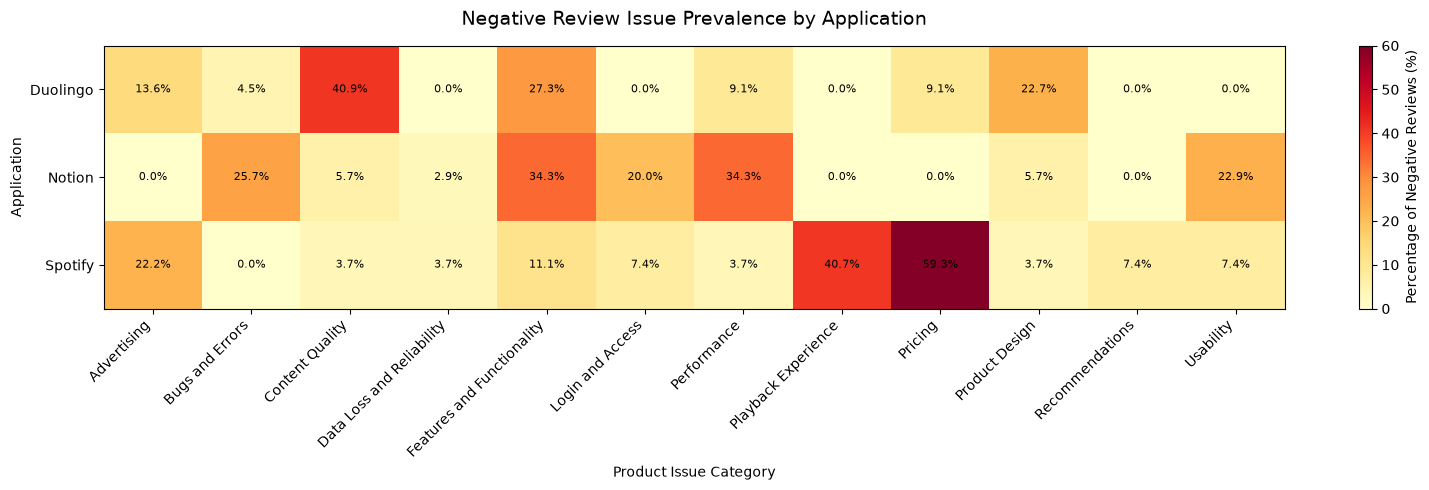

In [76]:

import matplotlib.pyplot as plt
import numpy as np

# Define the issue order
issue_order = [
    "Advertising",
    "Bugs and Errors",
    "Content Quality",
    "Data Loss and Reliability",
    "Features and Functionality",
    "Login and Access",
    "Performance",
    "Playback Experience",
    "Pricing",
    "Product Design",
    "Recommendations",
    "Usability"
]

# Arrange the data
heatmap_data = issue_prevalence.reindex(
    columns=issue_order,
    fill_value=0
)

# Create the heatmap
fig, ax = plt.subplots(figsize=(16, 5))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=60
)

# Add labels
ax.set_xticks(range(len(issue_order)))
ax.set_xticklabels(issue_order, rotation=45, ha="right")

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

# Add percentage values
for i in range(len(heatmap_data.index)):
    for j in range(len(issue_order)):
        value = heatmap_data.iloc[i, j]
        ax.text(
            j, i, f"{value:.1f}%",
            ha="center",
            va="center",
            fontsize=8
        )

ax.set_title(
    "Negative Review Issue Prevalence by Application",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Product Issue Category")
ax.set_ylabel("Application")

fig.colorbar(
    im,
    ax=ax,
    label="Percentage of Negative Reviews (%)"
)

plt.tight_layout()
plt.savefig(
    "../data/issue_prevalence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [77]:

# Select analysis-related columns
analysis_columns = [
    "app",
    "score",
    "at",
    "appVersion",
    "language_final",
    "pos",
    "neu",
    "neg",
    "compound",
    "sentiment",
    "sentiment_final",
    "validation_method",
    "rating_sentiment"
]

analysis_dataset = english_reviews[
    analysis_columns
].copy()

# Add issue labels to negative reviews
analysis_dataset["issues"] = None

analysis_dataset.loc[
    negative_reviews_final.index,
    "issues"
] = negative_reviews_final["issues"]

# Save the cleaned dataset
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

analysis_dataset.to_csv(
    output_dir / "english_reviews_analysis.csv",
    index=False
)

print("Dataset shape:", analysis_dataset.shape)
print("\nColumns:")
print(analysis_dataset.columns.tolist())

print("\nSentiment distribution:")
print(analysis_dataset["sentiment_final"].value_counts())


Dataset shape: (489, 14)

Columns:
['app', 'score', 'at', 'appVersion', 'language_final', 'pos', 'neu', 'neg', 'compound', 'sentiment', 'sentiment_final', 'validation_method', 'rating_sentiment', 'issues']

Sentiment distribution:
sentiment_final
Positive    346
Negative     84
Neutral      59
Name: count, dtype: int64


In [78]:

print("Dataset shape:", analysis_dataset.shape)

print("\nMissing values:")
print(analysis_dataset.isnull().sum())

print("\nReviews by app:")
print(analysis_dataset["app"].value_counts())

print("\nIssue labels example:")
print(
    analysis_dataset[
        analysis_dataset["issues"].notna()
    ][["app", "sentiment_final", "issues"]].head(10)
)


Dataset shape: (489, 14)

Missing values:
app                    0
score                  0
at                     0
appVersion            55
language_final         0
pos                    0
neu                    0
neg                    0
compound               0
sentiment              0
sentiment_final        0
validation_method      0
rating_sentiment       0
issues               405
dtype: int64

Reviews by app:
app
Notion      175
Duolingo    161
Spotify     153
Name: count, dtype: int64

Issue labels example:
       app sentiment_final                                          issues
3   Notion        Negative                 [Performance, Login and Access]
6   Notion        Negative                                [Product Design]
8   Notion        Negative                                              []
19  Notion        Negative                              [Login and Access]
21  Notion        Negative                    [Features and Functionality]
26  Notion        Negative 

In [79]:
analysis_dataset.to_csv(
    output_dir / "english_reviews_analysis.csv",
    index=False
)

In [80]:
negative_data = analysis_dataset[
    analysis_dataset["sentiment_final"] == "Negative"
]

labeled_count = negative_data["issues"].apply(len).gt(0).sum()
unlabeled_count = len(negative_data) - labeled_count

print("Total negative reviews:", len(negative_data))
print("Negative reviews with issue labels:", labeled_count)
print("Negative reviews without issue labels:", unlabeled_count)
print("Issue labeling coverage:", f"{labeled_count / len(negative_data) * 100:.2f}%")

Total negative reviews: 84
Negative reviews with issue labels: 78
Negative reviews without issue labels: 6
Issue labeling coverage: 92.86%


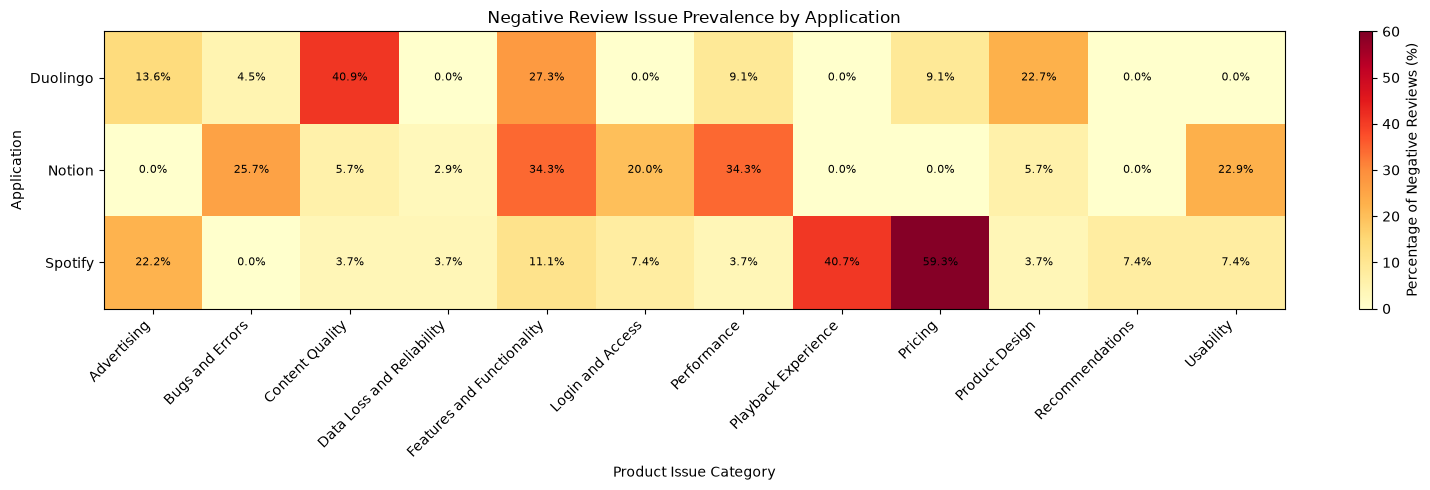

In [81]:
import matplotlib.pyplot as plt
from pathlib import Path

issue_order = [
    "Advertising",
    "Bugs and Errors",
    "Content Quality",
    "Data Loss and Reliability",
    "Features and Functionality",
    "Login and Access",
    "Performance",
    "Playback Experience",
    "Pricing",
    "Product Design",
    "Recommendations",
    "Usability"
]

heatmap_data = issue_prevalence.reindex(
    columns=issue_order,
    fill_value=0
)

fig, ax = plt.subplots(figsize=(16, 5))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="YlOrRd",
    vmin=0,
    vmax=60
)

ax.set_xticks(range(len(issue_order)))
ax.set_xticklabels(issue_order, rotation=45, ha="right")
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

for i in range(len(heatmap_data.index)):
    for j in range(len(issue_order)):
        value = heatmap_data.iloc[i, j]
        ax.text(
            j, i, f"{value:.1f}%",
            ha="center",
            va="center",
            fontsize=8
        )

ax.set_title("Negative Review Issue Prevalence by Application")
ax.set_xlabel("Product Issue Category")
ax.set_ylabel("Application")

fig.colorbar(
    im,
    ax=ax,
    label="Percentage of Negative Reviews (%)"
)

plt.tight_layout()

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "issue_prevalence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
